In [1]:
import os, random
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)            
tf.config.experimental.enable_op_determinism()  

import torch
torch.manual_seed(SEED)

In [4]:
# 100,000 features (DPD)
df1 = pd.read_csv('diabetes_dataset_with_notes.csv')


In [5]:
df1.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0,"Overweight, advised dietary and exercise modif..."
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0,Healthy BMI range.
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0,"Young patient, generally lower risk but needs ..."
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0,"Overweight, advised dietary and exercise modif..."
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0,"Healthy BMI range. High HbA1c level, indicativ..."


In [6]:

df1 = df1.drop(columns=['clinical_notes', 'location', 'year',
                        'race:AfricanAmerican', 'race:Asian', 'race:Caucasian',
                        'race:Hispanic', 'race:Other'])

# Gender: drop the 18 'Other' rows instead of relabelling them as Female\Male
print(df1['gender'].value_counts())
df1 = df1[df1['gender'] != 'Other'].copy()

# Smoking history: lowercase FIRST, then map using lowercase keys
df1['smoking_history'] = (df1['smoking_history']
                          .str.lower().str.strip()
                          .replace({'no info': 'unknown',
                                    'not current': 'former',
                                    'ever': 'former'}))
print(df1['smoking_history'].value_counts())   # should show: unknown, never, former, current

# Duplicates: remove exact duplicate rows so copies can't sit in both train and test
n_before = len(df1)
df1 = df1.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df1)} duplicate rows; {len(df1)} remain")
print(df1['diabetes'].value_counts(normalize=True))

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64
smoking_history
unknown    35810
never      35092
former     19794
current     9286
Name: count, dtype: int64
Removed 4032 duplicate rows; 95950 remain
diabetes
0    0.91161
1    0.08839
Name: proportion, dtype: float64


In [7]:
pd.DataFrame({
    "DType": df1.dtypes,
    "null_ratio": df1.isnull().sum(),
    "nunique": df1.nunique()
})

,DType,null_ratio,nunique
gender,object,0,2
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,object,0,4
bmi,float64,0,4247
hbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2


In [8]:
from sklearn.preprocessing import LabelEncoder


df1['gender'] = df1['gender'].map({'Female': 0, 'Male': 1})

le = LabelEncoder()
df1['smoking_history'] = le.fit_transform(df1['smoking_history'])

pd.DataFrame({"DType": df1.dtypes,
              "n_null": df1.isnull().sum(),
              "nunique": df1.nunique()})

,DType,n_null,nunique
gender,int64,0,2
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,int64,0,4
bmi,float64,0,4247
hbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2


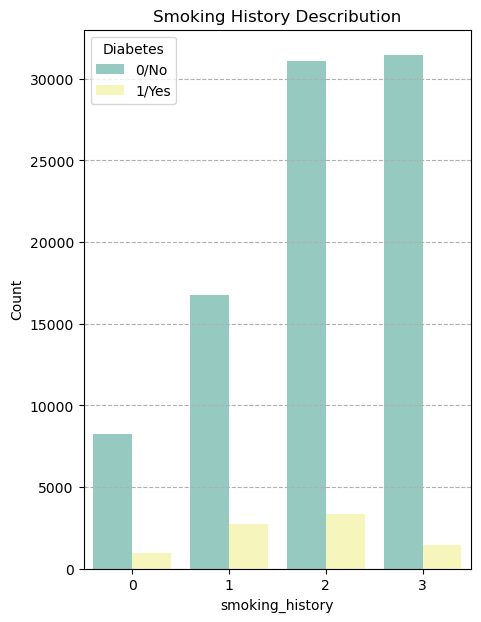

In [9]:
plt.figure(figsize=(5,7))
sns.countplot(x='smoking_history', hue='diabetes', data=df1, palette='Set3')
plt.title("Smoking History Describution")
plt.xlabel("smoking_history")
plt.ylabel("Count")
plt.legend(title="Diabetes", labels=["0/No", "1/Yes"])
plt.grid(axis='y',linestyle='--')
plt.show()

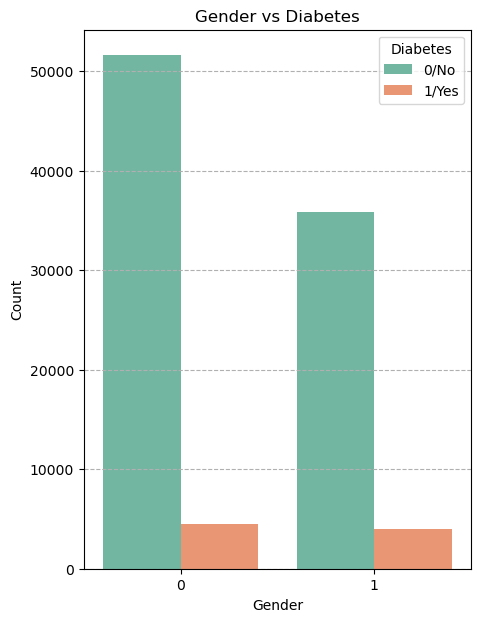

In [10]:
plt.figure(figsize=(5,7))
sns.countplot(x='gender', hue='diabetes', data=df1, palette='Set2')
plt.title("Gender vs Diabetes")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Diabetes", labels=["0/No", "1/Yes"])
plt.grid(axis='y',linestyle='--')
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

X = df1.drop(columns=['diabetes'])
y = df1['diabetes']
feature_names = X.columns.tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# Reset indices so .iloc in the CV loops lines up with the numpy arrays
y_train, y_val, y_test = [s.reset_index(drop=True) for s in (y_train, y_val, y_test)]

for name, s in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, len(s), "diabetic rate:", round(s.mean(), 4))

Train 67165 diabetic rate: 0.0884
Val 14392 diabetic rate: 0.0884
Test 14393 diabetic rate: 0.0884


In [ ]:
def count_outliers(df, columns):
    out = {}
    for col in columns:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        out[col] = int(((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum())
    return out

# HbA1c and blood glucose values are retained because extreme values may represent clinically meaningful observations.
print("IQR outliers (train):",
      count_outliers(X_train, ['age', 'bmi', 'hbA1c_level', 'blood_glucose_level']))

# Cap BMI only, using bounds from the training set
q1, q3 = X_train['bmi'].quantile([0.25, 0.75])
iqr = q3 - q1
bmi_low, bmi_high = q1 - 1.5*iqr, q3 + 1.5*iqr
for d in (X_train, X_val, X_test):
    d['bmi'] = d['bmi'].clip(bmi_low, bmi_high)
print(f"BMI capped to [{bmi_low:.2f}, {bmi_high:.2f}]")

IQR outliers (train): {'age': 0, 'bmi': 3634, 'hbA1c_level': 923, 'blood_glucose_level': 1407}
BMI capped to [13.62, 39.70]


In [ ]:
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)   # fit on training data only
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

y_train_arr = np.asarray(y_train)
print("Train range:", X_train.min(), X_train.max())
print("Val range:  ", X_val.min(), X_val.max())
print("Test range: ", X_test.min(), X_test.max())

In [ ]:
binary_idx = [feature_names.index(c) for c in ['gender', 'hypertension', 'heart_disease']]
smoke_idx = [i for i, c in enumerate(feature_names) if c.startswith('smoking_')]

def fix_synthetic(X):
    X = np.asarray(X, dtype=float).copy()
    X[:, binary_idx] = np.round(X[:, binary_idx])
    s = X[:, smoke_idx]
    onehot = np.zeros_like(s)
    onehot[np.arange(len(s)), s.argmax(axis=1)] = 1
    X[:, smoke_idx] = onehot
    return X

def best_threshold(y_true, prob):
    """Threshold that maximises F1 on the validation set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

def summarise(name, prob, thr):
    pred = (prob >= thr).astype(int)
    return {'Model': name, 'Threshold': thr,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob),
            'PR-AUC': average_precision_score(y_test, prob)}

def report(name, val_prob, test_prob):
    thr = best_threshold(y_val, val_prob)
    pred = (test_prob >= thr).astype(int)
    print(f"{name} (threshold = {thr:.3f}, chosen on validation)")
    print(classification_report(y_test, pred, digits=4))
    print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
    print("PR-AUC: ", round(average_precision_score(y_test, test_prob), 4))
    return thr

In [14]:
!pip install pandas numpy seaborn matplotlib scikit-learn tensorflow torch pytorch-tabnet smote-variants xgboost catboost shap

  Using cached smote_variants-1.0.1-py3-none-any.whl.metadata (35 kB)
  Using cached minisom-2.3.6.tar.gz (13 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached statistics-1.0.3.5.tar.gz (8.3 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached metric_learn-0.7.0-py2.py3-none-any.whl.metadata (5.2 kB)
  Using cached umf-1.1.0-py2.py3-none-win_amd64.whl.metadata (1.1 kB)
  Using cached tcmlib-1.5.0-py2.p


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\FaiMkri\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [15]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt

# ProWSyn will be applied inside each training fold during cross-validation.
X_train_meta = X_train
y_train_meta = y_train
X_test_meta = X_test
y_test_meta = y_test

print(f"Training data shape: {X_train_meta.shape}")
print(f"Training labels shape: {y_train_meta.shape}")
print(f"Test data shape: {X_test_meta.shape}")
print(f"Test labels shape: {y_test_meta.shape}")

Training data shape: (67165, 11)
Training labels shape: (67165,)
Test data shape: (14393, 11)
Test labels shape: (14393,)


In [ ]:
# CELL: DNN Training with Cross-Validation

import smote_variants as sv
from collections import Counter
from sklearn.model_selection import StratifiedKFold, train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.metrics import Recall

N_FOLDS = 5

# Initialize OOF, test and validation prediction arrays
oof_dnn = np.zeros(len(X_train_meta))
test_dnn = np.zeros(len(X_test_meta))
val_dnn = np.zeros(len(X_val))

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"DNN FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]              # NumPy array
    y_fold_train = y_train_meta.iloc[train_idx].copy()  # Pandas Series, positional indexing

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx].copy()

    # Early-stopping set taken from the TRAINING part of the fold,
    # so the OOF rows (X_fold_val) are never seen during training
    X_fold_train, X_es, y_fold_train, y_es = train_test_split(
        X_fold_train, y_fold_train, test_size=0.1,
        stratify=y_fold_train, random_state=SEED)

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print(f"Fold train: {X_fold_train.shape}")
    print(f"Early-stopping set: {X_es.shape}")
    print(f"Fold validation (OOF): {X_fold_val.shape}")
    print(f"Training class distribution after ProWSyn: {Counter(y_fold_train)}")

    # Build DNN model
    model_dnn = Sequential([
        Input(shape=(X_fold_train.shape[1],)),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(64, activation='tanh'),
        Dropout(0.3),
        Dense(32, activation='tanh'),
        Dropout(0.25),
        Dense(16, activation='tanh'),
        Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(4, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model_dnn.compile(
        optimizer=AdamW(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', Recall(name='recall')]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    # Train
    history_dnn = model_dnn.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_es, y_es),        
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    # OOF prediction
    oof_dnn[val_idx] = model_dnn.predict(X_fold_val, verbose=0).ravel()

    # Test and validation predictions (averaged over folds)
    test_dnn += model_dnn.predict(X_test_meta, verbose=0).ravel() / N_FOLDS
    val_dnn += model_dnn.predict(X_val, verbose=0).ravel() / N_FOLDS

print("\nDNN OOF, validation and test predictions completed!")

2026-10-01 12:48:26,640:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-10-01 12:48:26,642:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:48:26,648:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



DNN FOLD 1/5


2026-10-01 12:48:27,157:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:48:27,160:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-10-01 12:48:27,477:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:48:27,479:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-10-01 12:48:27,701:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:48:27,702:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-10-01 12:48:27,841:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:48:27,843:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-10-01 12:48:27,937:INFO:ProWSyn: simplex sampling with n_dim 2
2026-10-01 12:49:55,288:INFO:ProWSyn: simplex sampling with n_dim 2
2026-10-01 12:49:56,116:INFO:ProWSyn: simplex sampling with n_dim 2
2026-10-01 12:49:56,464:INFO:ProWSyn: simplex sampli

Fold train: (88166, 11)
Early-stopping set: (5374, 11)
Fold validation (OOF): (13433, 11)
Training class distribution after ProWSyn: Counter({np.int64(0): 44083, np.int64(1): 44083})
Epoch 1/40
1378/1378 ━━━━━━━━━━━━━━━━━━━━ 2s 949us/step - accuracy: 0.8643 - loss: 0.3086 - recall: 0.9004 - val_accuracy: 0.8433 - val_loss: 0.3201 - val_recall: 0.9305
Epoch 2/40
1378/1378 ━━━━━━━━━━━━━━━━━━━━ 1s 871us/step - accuracy: 0.8933 - loss: 0.2500 - recall: 0.9313 - val_accuracy: 0.8470 - val_loss: 0.2931 - val_recall: 0.9368
Epoch 3/40
1378/1378 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8960 - loss: 0.2373 - recall: 0.9352 - val_accuracy: 0.8379 - val_loss: 0.3060 - val_recall: 0.9516
Epoch 4/40
1378/1378 ━━━━━━━━━━━━━━━━━━━━ 1s 917us/step - accuracy: 0.8974 - loss: 0.2312 - recall: 0.9338 - val_accuracy: 0.8465 - val_loss: 0.2944 - val_recall: 0.9326
Epoch 5/40
1378/1378 ━━━━━━━━━━━━━━━━━━━━ 1s 812us/step - accuracy: 0.8992 - loss: 0.2277 - recall: 0.9330 - val_accuracy: 0.8539 - val_los

2026-10-01 12:50:27,197:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-10-01 12:50:27,199:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:50:27,206:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



DNN FOLD 2/5


2026-10-01 12:50:27,704:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:50:27,707:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-10-01 12:50:28,009:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:50:28,011:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-10-01 12:50:28,230:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:50:28,232:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-10-01 12:50:28,388:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-10-01 12:50:28,389:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-10-01 12:50:28,475:INFO:ProWSyn: simplex sampling with n_dim 2
2026-10-01 12:52:04,734:INFO:ProWSyn: simplex sampling with n_dim 2
2026-10-01 12:52:05,532:INFO:ProWSyn: simplex sampling with n_dim 2
2026-10-01 12:52:05,808:INFO:ProWSyn: simplex sampli

Fold train: (88166, 11)
Early-stopping set: (5374, 11)
Fold validation (OOF): (13433, 11)
Training class distribution after ProWSyn: Counter({np.int64(0): 44083, np.int64(1): 44083})
Epoch 1/40
1378/1378 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.8680 - loss: 0.3072 - recall: 0.9123 - val_accuracy: 0.8588 - val_loss: 0.2547 - val_recall: 0.9053
Epoch 2/40
1378/1378 ━━━━━━━━━━━━━━━━━━━━ 1s 873us/step - accuracy: 0.8969 - loss: 0.2434 - recall: 0.9405 - val_accuracy: 0.8480 - val_loss: 0.2484 - val_recall: 0.9326
Epoch 3/40
1378/1378 ━━━━━━━━━━━━━━━━━━━━ 1s 862us/step - accuracy: 0.9003 - loss: 0.2316 - recall: 0.9438 - val_accuracy: 0.8528 - val_loss: 0.2509 - val_recall: 0.9326
Epoch 4/40
1363/1378 ━━━━━━━━━━━━━━━━━━━━ 0s 815us/step - accuracy: 0.9021 - loss: 0.2266 - recall: 0.9452

In [ ]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, precision_recall_curve)

def best_threshold(y_true, prob):
    """Threshold that maximises F1 on the validation set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]

dnn_thr = best_threshold(y_val, val_dnn)          # chosen on VALIDATION
dnn_pred = (test_dnn >= dnn_thr).astype(int)      # applied to TEST (fold-averaged)

print(f"DNN Results (threshold = {dnn_thr:.3f}, chosen on validation)")
print(classification_report(y_test, dnn_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_dnn), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_dnn), 4))

DNN Results (threshold = 0.881, chosen on validation)
              precision    recall  f1-score   support

           0     0.9672    0.9922    0.9795     13121
           1     0.8906    0.6525    0.7532      1272

    accuracy                         0.9622     14393
   macro avg     0.9289    0.8224    0.8664     14393
weighted avg     0.9604    0.9622    0.9595     14393

ROC-AUC: 0.9683
PR-AUC: 0.8423


In [ ]:
# CELL: TabNet Training with Cross-Validation

from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.model_selection import train_test_split
import torch
import smote_variants as sv
from collections import Counter

# Initialize OOF, test and validation prediction arrays
oof_tabnet = np.zeros(len(X_train_meta))
test_tabnet = np.zeros(len(X_test_meta))
val_tabnet = np.zeros(len(X_val))

tabnet_models = []    

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"TABNET FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = np.asarray(y_train_meta.iloc[val_idx])

    # Early-stopping set taken from the TRAINING part of the fold
    X_fold_train, X_es, y_fold_train, y_es = train_test_split(
        X_fold_train, y_fold_train, test_size=0.1,
        stratify=y_fold_train, random_state=SEED)

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print("Training class distribution:", Counter(y_fold_train))
    print(f"Early-stopping set: {X_es.shape}")
    print(f"Validation (OOF) shape: {X_fold_val.shape}")

    # Build model
    tabnet_model = TabNetClassifier(
        n_d=16,
        n_a=16,
        n_steps=7,
        gamma=1.5,
        lambda_sparse=1e-2,
        optimizer_fn=torch.optim.AdamW,
        optimizer_params=dict(lr=0.005),
        seed=SEED + fold,
        verbose=1
    )

    # Train
    tabnet_model.fit(
        X_fold_train,
        y_fold_train,
        eval_set=[(X_es, np.asarray(y_es))],   
        eval_name=['es'],
        eval_metric=['auc'],
        max_epochs=50,
        patience=5,
        batch_size=1024,
        virtual_batch_size=128
    )

    tabnet_models.append(tabnet_model)         

    # OOF prediction
    oof_tabnet[val_idx] = tabnet_model.predict_proba(X_fold_val)[:, 1]

    # Test and validation predictions (averaged over folds)
    test_tabnet += tabnet_model.predict_proba(X_test_meta)[:, 1] / N_FOLDS
    val_tabnet += tabnet_model.predict_proba(X_val)[:, 1] / N_FOLDS

print("\nTabNet OOF, validation and test predictions completed!")


TABNET FOLD 1/5


2026-09-30 16:48:55,646:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 16:48:55,650:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 16:48:55,658:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 16:48:56,178:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 16:48:56,182:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 16:48:56,563:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 16:48:56,565:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 16:48:56,794:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 16:48:

Training class distribution: Counter({np.int64(0): 44083, np.int64(1): 44083})
Early-stopping set: (5374, 11)
Validation (OOF) shape: (13433, 11)
epoch 0  | loss: 0.43473 | es_auc: 0.89833 |  0:00:04s
epoch 1  | loss: 0.27598 | es_auc: 0.93714 |  0:00:08s
epoch 2  | loss: 0.25499 | es_auc: 0.9612  |  0:00:12s
epoch 3  | loss: 0.24208 | es_auc: 0.96756 |  0:00:16s
epoch 4  | loss: 0.23608 | es_auc: 0.97055 |  0:00:20s
epoch 5  | loss: 0.22448 | es_auc: 0.96726 |  0:00:24s
epoch 6  | loss: 0.22755 | es_auc: 0.96792 |  0:00:27s
epoch 7  | loss: 0.21802 | es_auc: 0.97181 |  0:00:31s
epoch 8  | loss: 0.21379 | es_auc: 0.969   |  0:00:35s
epoch 9  | loss: 0.21414 | es_auc: 0.97002 |  0:00:39s
epoch 10 | loss: 0.20661 | es_auc: 0.97194 |  0:00:43s
epoch 11 | loss: 0.20578 | es_auc: 0.9697  |  0:00:47s
epoch 12 | loss: 0.20456 | es_auc: 0.97031 |  0:00:51s
epoch 13 | loss: 0.20102 | es_auc: 0.9708  |  0:00:55s
epoch 14 | loss: 0.20047 | es_auc: 0.97003 |  0:00:59s
epoch 15 | loss: 0.1984  | es

c:\Users\FaiMkri\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
2026-09-30 16:51:42,809:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 16:51:42,812:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 16:51:42,820:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



TABNET FOLD 2/5


...


TABNET FOLD 5/5


2026-09-30 17:00:05,865:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:00:05,868:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:00:06,194:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:00:06,196:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:00:06,438:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:00:06,440:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:00:06,591:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:00:06,592:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:00:06,682:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:01:38,812:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:01:39,798:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:01:40,303:INFO:ProWSyn: simplex sampli

Training class distribution: Counter({np.int64(0): 44084, np.int64(1): 44084})
Early-stopping set: (5374, 11)
Validation (OOF) shape: (13433, 11)
epoch 0  | loss: 0.4131  | es_auc: 0.90705 |  0:00:04s
epoch 1  | loss: 0.27733 | es_auc: 0.93931 |  0:00:08s
epoch 2  | loss: 0.25433 | es_auc: 0.95558 |  0:00:12s
epoch 3  | loss: 0.23695 | es_auc: 0.96528 |  0:00:16s
epoch 4  | loss: 0.23417 | es_auc: 0.96306 |  0:00:20s
epoch 5  | loss: 0.23258 | es_auc: 0.96307 |  0:00:24s
epoch 6  | loss: 0.22423 | es_auc: 0.96357 |  0:00:29s
epoch 7  | loss: 0.22023 | es_auc: 0.96208 |  0:00:33s
epoch 8  | loss: 0.21905 | es_auc: 0.96348 |  0:00:37s

Early stopping occurred at epoch 8 with best_epoch = 3 and best_es_auc = 0.96528


c:\Users\FaiMkri\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



TabNet OOF, validation and test predictions completed!


In [ ]:
tabnet_thr = best_threshold(y_val, val_tabnet)          # chosen on VALIDATION
tabnet_pred = (test_tabnet >= tabnet_thr).astype(int)   # applied to TEST (fold-averaged)

print(f"TabNet Results (threshold = {tabnet_thr:.3f}, chosen on validation)")
print(classification_report(y_test, tabnet_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_tabnet), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_tabnet), 4))

TabNet Results (threshold = 0.851, chosen on validation)
              precision    recall  f1-score   support

           0     0.9709    0.9909    0.9808     13121
           1     0.8804    0.6942    0.7763      1272

    accuracy                         0.9646     14393
   macro avg     0.9257    0.8425    0.8785     14393
weighted avg     0.9629    0.9646    0.9627     14393

ROC-AUC: 0.972
PR-AUC: 0.8605


In [ ]:
# CELL: ResNet (tabular, with residual connections) Training with Cross-Validation

from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from sklearn.model_selection import train_test_split
from collections import Counter
import smote_variants as sv


def build_resnet(n_features, width=64, n_blocks=3, dropout=0.2):
    inp = layers.Input(shape=(n_features,))
    x = layers.Dense(width)(inp)
    for _ in range(n_blocks):
        h = layers.BatchNormalization()(x)
        h = layers.Dense(width * 2, activation='relu')(h)
        h = layers.Dropout(dropout)(h)
        h = layers.Dense(width)(h)
        x = layers.Add()([x, h])         
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return Model(inp, out)


# Initialize OOF, test and validation prediction arrays
oof_resnet = np.zeros(len(X_train_meta))
test_resnet = np.zeros(len(X_test_meta))
val_resnet = np.zeros(len(X_val))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"RESNET FOLD {fold}/{N_FOLDS}")
    print("=" * 60)

    # Split data
    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx].copy()

    # Early-stopping set taken from the TRAINING part of the fold
    X_fold_train, X_es, y_fold_train, y_es = train_test_split(
        X_fold_train, y_fold_train, test_size=0.1,
        stratify=y_fold_train, random_state=SEED)

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=SEED
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )
    X_fold_train = fix_synthetic(X_fold_train)

    print("Training class distribution:", Counter(y_fold_train))
    print(f"Early-stopping set: {X_es.shape}")
    print(f"Validation (OOF) shape: {X_fold_val.shape}")

    # Build model
    resnet_model = build_resnet(X_fold_train.shape[1])

    resnet_model.compile(
        optimizer=AdamW(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    history = resnet_model.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_es, y_es),    
        epochs=100,
        batch_size=1024,
        callbacks=[early_stop],
        verbose=1
    )

    # OOF prediction
    oof_resnet[val_idx] = resnet_model.predict(X_fold_val, verbose=0).ravel()

    # Test and validation predictions (averaged over folds)
    test_resnet += resnet_model.predict(X_test_meta, verbose=0).ravel() / N_FOLDS
    val_resnet += resnet_model.predict(X_val, verbose=0).ravel() / N_FOLDS

print("\nResNet OOF, validation and test predictions completed!")

2026-09-30 17:02:21,020:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 17:02:21,024:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:02:21,034:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



RESNET FOLD 1/5


2026-09-30 17:02:21,552:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:02:21,555:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:02:21,926:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:02:21,928:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:02:22,157:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:02:22,159:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:02:22,301:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:02:22,302:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:02:22,398:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:03:51,508:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:03:52,229:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:03:52,559:INFO:ProWSyn: simplex sampli

Training class distribution: Counter({np.int64(0): 44083, np.int64(1): 44083})
Early-stopping set: (5374, 11)
Validation (OOF) shape: (13433, 11)
Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8650 - loss: 0.2985 - val_accuracy: 0.2918 - val_loss: 1.5245
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8922 - loss: 0.2464 - val_accuracy: 0.5675 - val_loss: 0.7274
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8963 - loss: 0.2377 - val_accuracy: 0.7198 - val_loss: 0.4907
Epoch 4/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8989 - loss: 0.2303 - val_accuracy: 0.8072 - val_loss: 0.3429
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9009 - loss: 0.2235 - val_accuracy: 0.8435 - val_loss: 0.2727
Epoch 6/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9017 - loss: 0.2193 - val_accuracy: 0.8534 - val_loss: 0.2605
Epoch 7/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9022 - loss: 0.2164 - val_a

2026-09-30 17:04:38,106:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 17:04:38,109:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:04:38,118:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski


...

Training class distribution: Counter({np.int64(0): 44084, np.int64(1): 44084})
Early-stopping set: (5374, 11)
Validation (OOF) shape: (13433, 11)
Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8671 - loss: 0.2987 - val_accuracy: 0.3606 - val_loss: 1.2165
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8954 - loss: 0.2417 - val_accuracy: 0.6009 - val_loss: 0.6935
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8996 - loss: 0.2303 - val_accuracy: 0.7592 - val_loss: 0.4354
Epoch 4/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9015 - loss: 0.2238 - val_accuracy: 0.8277 - val_loss: 0.3213
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9041 - loss: 0.2189 - val_accuracy: 0.8398 - val_loss: 0.2950
Epoch 6/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9042 - loss: 0.2155 - val_accuracy: 0.8480 - val_loss: 0.2916
Epoch 7/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9054 - loss: 0.2129 - val_a

2026-09-30 17:11:23,171:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-30 17:11:23,174:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:11:23,183:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



RESNET FOLD 5/5


2026-09-30 17:11:23,706:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:11:23,709:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:11:24,054:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:11:24,057:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:11:24,317:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:11:24,318:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:11:24,469:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-30 17:11:24,470:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-30 17:11:24,559:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:13:02,416:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:13:03,340:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-30 17:13:03,740:INFO:ProWSyn: simplex sampli

Training class distribution: Counter({np.int64(0): 44084, np.int64(1): 44084})
Early-stopping set: (5374, 11)
Validation (OOF) shape: (13433, 11)
Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8644 - loss: 0.2996 - val_accuracy: 0.3908 - val_loss: 1.2007
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8935 - loss: 0.2439 - val_accuracy: 0.6377 - val_loss: 0.6277
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8980 - loss: 0.2333 - val_accuracy: 0.7546 - val_loss: 0.4470
Epoch 4/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9000 - loss: 0.2261 - val_accuracy: 0.8160 - val_loss: 0.3410
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9020 - loss: 0.2206 - val_accuracy: 0.8409 - val_loss: 0.2888
Epoch 6/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9030 - loss: 0.2177 - val_accuracy: 0.8450 - val_loss: 0.2928
Epoch 7/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9045 - loss: 0.2138 - val_a

In [ ]:
resnet_thr = best_threshold(y_val, val_resnet)          # chosen on VALIDATION
resnet_pred = (test_resnet >= resnet_thr).astype(int)   # applied to TEST (fold-averaged)

print(f"ResNet Results (threshold = {resnet_thr:.3f}, chosen on validation)")
print(classification_report(y_test, resnet_pred, digits=4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_resnet), 4))
print("PR-AUC:", round(average_precision_score(y_test, test_resnet), 4))

ResNet Results (threshold = 0.899, chosen on validation)
              precision    recall  f1-score   support

           0     0.9690    0.9974    0.9830     13121
           1     0.9617    0.6714    0.7907      1272

    accuracy                         0.9686     14393
   macro avg     0.9654    0.8344    0.8869     14393
weighted avg     0.9684    0.9686    0.9660     14393

ROC-AUC: 0.9725
PR-AUC: 0.8621


In [22]:
# Meta-features

from sklearn.preprocessing import StandardScaler


# DNN + TabNet
X_meta_dt_train = np.column_stack([oof_dnn, oof_tabnet])
X_meta_dt_val   = np.column_stack([val_dnn, val_tabnet])
X_meta_dt_test  = np.column_stack([test_dnn, test_tabnet])

scaler_dt = StandardScaler()
X_meta_dt_train_scaled = scaler_dt.fit_transform(X_meta_dt_train)
X_meta_dt_val_scaled   = scaler_dt.transform(X_meta_dt_val)
X_meta_dt_test_scaled  = scaler_dt.transform(X_meta_dt_test)


# DNN + ResNet
X_meta_dr_train = np.column_stack([oof_dnn, oof_resnet])
X_meta_dr_val   = np.column_stack([val_dnn, val_resnet])
X_meta_dr_test  = np.column_stack([test_dnn, test_resnet])

scaler_dr = StandardScaler()
X_meta_dr_train_scaled = scaler_dr.fit_transform(X_meta_dr_train)
X_meta_dr_val_scaled   = scaler_dr.transform(X_meta_dr_val)
X_meta_dr_test_scaled  = scaler_dr.transform(X_meta_dr_test)


# TabNet + ResNet
X_meta_tr_train = np.column_stack([oof_tabnet, oof_resnet])
X_meta_tr_val   = np.column_stack([val_tabnet, val_resnet])
X_meta_tr_test  = np.column_stack([test_tabnet, test_resnet])

scaler_tr = StandardScaler()
X_meta_tr_train_scaled = scaler_tr.fit_transform(X_meta_tr_train)
X_meta_tr_val_scaled   = scaler_tr.transform(X_meta_tr_val)
X_meta_tr_test_scaled  = scaler_tr.transform(X_meta_tr_test)


# DNN + TabNet + ResNet
X_meta_all_train = np.column_stack([oof_dnn, oof_tabnet, oof_resnet])
X_meta_all_val   = np.column_stack([val_dnn, val_tabnet, val_resnet])
X_meta_all_test  = np.column_stack([test_dnn, test_tabnet, test_resnet])

scaler_all = StandardScaler()
X_meta_all_train_scaled = scaler_all.fit_transform(X_meta_all_train)
X_meta_all_val_scaled   = scaler_all.transform(X_meta_all_val)
X_meta_all_test_scaled  = scaler_all.transform(X_meta_all_test)

In [23]:
from catboost import CatBoostClassifier


# DNN + TabNet
catboost_dt = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_dt.fit(
    X_meta_dt_train,
    y_train
)

catboost_dt_prob = catboost_dt.predict_proba(
    X_meta_dt_test
)[:, 1]

catboost_dt_thr = best_threshold(
    y_val, catboost_dt.predict_proba(X_meta_dt_val)[:, 1])
catboost_dt_pred = (catboost_dt_prob >= catboost_dt_thr).astype(int)



# DNN + ResNet
catboost_dr = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_dr.fit(
    X_meta_dr_train,
    y_train
)

catboost_dr_prob = catboost_dr.predict_proba(
    X_meta_dr_test
)[:, 1]

catboost_dr_thr = best_threshold(
    y_val, catboost_dr.predict_proba(X_meta_dr_val)[:, 1])
catboost_dr_pred = (catboost_dr_prob >= catboost_dr_thr).astype(int)



# TabNet + ResNet
catboost_tr = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_tr.fit(
    X_meta_tr_train,
    y_train
)

catboost_tr_prob = catboost_tr.predict_proba(
    X_meta_tr_test
)[:, 1]

catboost_tr_thr = best_threshold(
    y_val, catboost_tr.predict_proba(X_meta_tr_val)[:, 1])
catboost_tr_pred = (catboost_tr_prob >= catboost_tr_thr).astype(int)



# DNN + TabNet + ResNet
catboost_all = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_all.fit(
    X_meta_all_train,
    y_train
)

catboost_all_prob = catboost_all.predict_proba(
    X_meta_all_test
)[:, 1]

catboost_all_thr = best_threshold(
    y_val, catboost_all.predict_proba(X_meta_all_val)[:, 1])
catboost_all_pred = (catboost_all_prob >= catboost_all_thr).astype(int)


# Show the chosen thresholds
print(f"Thresholds (chosen on validation): "
      f"DT={catboost_dt_thr:.3f}  DR={catboost_dr_thr:.3f}  "
      f"TR={catboost_tr_thr:.3f}  ALL={catboost_all_thr:.3f}")

Thresholds (chosen on validation): DT=0.373  DR=0.454  TR=0.294  ALL=0.315


In [24]:
# Evaluate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
catboost_dt_results = {
    'Model': 'CatBoost: DNN + TabNet',
    'Threshold': catboost_dt_thr,
    'Accuracy': accuracy_score(y_test, catboost_dt_pred),
    'Precision': precision_score(y_test, catboost_dt_pred),
    'Recall': recall_score(y_test, catboost_dt_pred),
    'F1': f1_score(y_test, catboost_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_dt_prob),
    'PR-AUC': average_precision_score(y_test, catboost_dt_prob)
}


# DNN + ResNet
catboost_dr_results = {
    'Model': 'CatBoost: DNN + ResNet',
    'Threshold': catboost_dr_thr,
    'Accuracy': accuracy_score(y_test, catboost_dr_pred),
    'Precision': precision_score(y_test, catboost_dr_pred),
    'Recall': recall_score(y_test, catboost_dr_pred),
    'F1': f1_score(y_test, catboost_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_dr_prob),
    'PR-AUC': average_precision_score(y_test, catboost_dr_prob)
}

# TabNet + ResNet
catboost_tr_results = {
    'Model': 'CatBoost: TabNet + ResNet',
    'Threshold': catboost_tr_thr,
    'Accuracy': accuracy_score(y_test, catboost_tr_pred),
    'Precision': precision_score(y_test, catboost_tr_pred),
    'Recall': recall_score(y_test, catboost_tr_pred),
    'F1': f1_score(y_test, catboost_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_tr_prob),
    'PR-AUC': average_precision_score(y_test, catboost_tr_prob)
}


# DNN + TabNet + ResNet
catboost_all_results = {
    'Model': 'CatBoost: DNN + TabNet + ResNet',
    'Threshold': catboost_all_thr,
    'Accuracy': accuracy_score(y_test, catboost_all_pred),
    'Precision': precision_score(y_test, catboost_all_pred),
    'Recall': recall_score(y_test, catboost_all_pred),
    'F1': f1_score(y_test, catboost_all_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_all_prob),
    'PR-AUC': average_precision_score(y_test, catboost_all_prob)
}

# Combine Results

catboost_results = pd.DataFrame([
    catboost_dt_results,
    catboost_dr_results,
    catboost_tr_results,
    catboost_all_results
])

catboost_results

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,CatBoost: DNN + TabNet,0.373465,0.965956,0.954651,0.645440,0.770169,0.971412,0.857809
1,CatBoost: DNN + ResNet,0.453525,0.969777,0.992933,0.662736,0.794908,0.972467,0.863144
2,CatBoost: TabNet + ResNet,0.294058,0.968179,0.954241,0.672170,0.788745,0.973034,0.864316
3,CatBoost: DNN + TabNet + ResNet,0.314844,0.967901,0.944079,0.676887,0.788462,0.972775,0.864694


In [25]:
from xgboost import XGBClassifier


# DNN + TabNet
xgb_dt = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_dt.fit(
    X_meta_dt_train,
    y_train
)

xgb_dt_prob = xgb_dt.predict_proba(
    X_meta_dt_test
)[:, 1]

xgb_dt_thr = best_threshold(
    y_val, xgb_dt.predict_proba(X_meta_dt_val)[:, 1])
xgb_dt_pred = (xgb_dt_prob >= xgb_dt_thr).astype(int)



# DNN + ResNet
xgb_dr = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_dr.fit(
    X_meta_dr_train,
    y_train
)

xgb_dr_prob = xgb_dr.predict_proba(
    X_meta_dr_test
)[:, 1]

xgb_dr_thr = best_threshold(
    y_val, xgb_dr.predict_proba(X_meta_dr_val)[:, 1])
xgb_dr_pred = (xgb_dr_prob >= xgb_dr_thr).astype(int)


# TabNet + ResNet
xgb_tr = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_tr.fit(
    X_meta_tr_train,
    y_train
)

xgb_tr_prob = xgb_tr.predict_proba(
    X_meta_tr_test
)[:, 1]

xgb_tr_thr = best_threshold(
    y_val, xgb_tr.predict_proba(X_meta_tr_val)[:, 1])
xgb_tr_pred = (xgb_tr_prob >= xgb_tr_thr).astype(int)


# DNN + TabNet + ResNet
xgb_all = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_all.fit(
    X_meta_all_train,
    y_train
)

xgb_all_prob = xgb_all.predict_proba(
    X_meta_all_test
)[:, 1]

xgb_all_thr = best_threshold(
    y_val, xgb_all.predict_proba(X_meta_all_val)[:, 1])
xgb_all_pred = (xgb_all_prob >= xgb_all_thr).astype(int)


# Show the chosen thresholds
print(f"Thresholds (chosen on validation): "
      f"DT={xgb_dt_thr:.3f}  DR={xgb_dr_thr:.3f}  "
      f"TR={xgb_tr_thr:.3f}  ALL={xgb_all_thr:.3f}")

Thresholds (chosen on validation): DT=0.292  DR=0.370  TR=0.362  ALL=0.375


In [26]:
# Evaluate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
xgb_dt_results = {
    'Model': 'XGBoost: DNN + TabNet',
    'Threshold': xgb_dt_thr,
    'Accuracy': accuracy_score(y_test, xgb_dt_pred),
    'Precision': precision_score(y_test, xgb_dt_pred),
    'Recall': recall_score(y_test, xgb_dt_pred),
    'F1': f1_score(y_test, xgb_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_dt_prob),
    'PR-AUC': average_precision_score(y_test, xgb_dt_prob)
}

# DNN + ResNet
xgb_dr_results = {
    'Model': 'XGBoost: DNN + ResNet',
    'Threshold': xgb_dr_thr,
    'Accuracy': accuracy_score(y_test, xgb_dr_pred),
    'Precision': precision_score(y_test, xgb_dr_pred),
    'Recall': recall_score(y_test, xgb_dr_pred),
    'F1': f1_score(y_test, xgb_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_dr_prob),
    'PR-AUC': average_precision_score(y_test, xgb_dr_prob)
}

# TabNet + ResNet
xgb_tr_results = {
    'Model': 'XGBoost: TabNet + ResNet',
    'Threshold': xgb_tr_thr,
    'Accuracy': accuracy_score(y_test, xgb_tr_pred),
    'Precision': precision_score(y_test, xgb_tr_pred),
    'Recall': recall_score(y_test, xgb_tr_pred),
    'F1': f1_score(y_test, xgb_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_tr_prob),
    'PR-AUC': average_precision_score(y_test, xgb_tr_prob)
}

# DNN + TabNet + ResNet
xgb_all_results = {
    'Model': 'XGBoost: DNN + TabNet + ResNet',
    'Threshold': xgb_all_thr,
    'Accuracy': accuracy_score(y_test, xgb_all_pred),
    'Precision': precision_score(y_test, xgb_all_pred),
    'Recall': recall_score(y_test, xgb_all_pred),
    'F1': f1_score(y_test, xgb_all_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_all_prob),
    'PR-AUC': average_precision_score(y_test, xgb_all_prob)
}

# Combined Results
xgb_results = pd.DataFrame([
    xgb_dt_results,
    xgb_dr_results,
    xgb_tr_results,
    xgb_all_results
])

xgb_results

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost: DNN + TabNet,0.292152,0.964705,0.889002,0.686321,0.774623,0.970938,0.856424
1,XGBoost: DNN + ResNet,0.370241,0.969360,0.973774,0.671384,0.794788,0.971790,0.860708
2,XGBoost: TabNet + ResNet,0.361771,0.969291,0.977011,0.668239,0.793651,0.972751,0.863489
3,XGBoost: DNN + TabNet + ResNet,0.374967,0.969499,0.980392,0.668239,0.794764,0.972667,0.863961


In [27]:
from sklearn.linear_model import LogisticRegression


# DNN + TabNet
lr_dt = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_dt.fit(
    X_meta_dt_train_scaled,
    y_train
)

lr_dt_prob = lr_dt.predict_proba(
    X_meta_dt_test_scaled
)[:, 1]

lr_dt_thr = best_threshold(
    y_val, lr_dt.predict_proba(X_meta_dt_val_scaled)[:, 1])
lr_dt_pred = (lr_dt_prob >= lr_dt_thr).astype(int)



# DNN + ResNet
lr_dr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_dr.fit(
    X_meta_dr_train_scaled,
    y_train
)

lr_dr_prob = lr_dr.predict_proba(
    X_meta_dr_test_scaled
)[:, 1]

lr_dr_thr = best_threshold(
    y_val, lr_dr.predict_proba(X_meta_dr_val_scaled)[:, 1])
lr_dr_pred = (lr_dr_prob >= lr_dr_thr).astype(int)



# TabNet + ResNet
lr_tr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tr.fit(
    X_meta_tr_train_scaled,
    y_train
)

lr_tr_prob = lr_tr.predict_proba(
    X_meta_tr_test_scaled
)[:, 1]

lr_tr_thr = best_threshold(
    y_val, lr_tr.predict_proba(X_meta_tr_val_scaled)[:, 1])
lr_tr_pred = (lr_tr_prob >= lr_tr_thr).astype(int)


# DNN + TabNet + ResNet
lr_all = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_all.fit(
    X_meta_all_train_scaled,
    y_train
)

lr_all_prob = lr_all.predict_proba(
    X_meta_all_test_scaled
)[:, 1]

lr_all_thr = best_threshold(
    y_val, lr_all.predict_proba(X_meta_all_val_scaled)[:, 1])
lr_all_pred = (lr_all_prob >= lr_all_thr).astype(int)


# Show the chosen thresholds
print(f"Thresholds (chosen on validation): "
      f"DT={lr_dt_thr:.3f}  DR={lr_dr_thr:.3f}  "
      f"TR={lr_tr_thr:.3f}  ALL={lr_all_thr:.3f}")

Thresholds (chosen on validation): DT=0.578  DR=0.594  TR=0.686  ALL=0.645


In [28]:
# Evaluate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
lr_dt_results = {
    'Model': 'Logistic Regression: DNN + TabNet',
    'Threshold': lr_dt_thr,
    'Accuracy': accuracy_score(y_test, lr_dt_pred),
    'Precision': precision_score(y_test, lr_dt_pred),
    'Recall': recall_score(y_test, lr_dt_pred),
    'F1': f1_score(y_test, lr_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_dt_prob),
    'PR-AUC': average_precision_score(y_test, lr_dt_prob)
}

# DNN + ResNet
lr_dr_results = {
    'Model': 'Logistic Regression: DNN + ResNet',
    'Threshold': lr_dr_thr,
    'Accuracy': accuracy_score(y_test, lr_dr_pred),
    'Precision': precision_score(y_test, lr_dr_pred),
    'Recall': recall_score(y_test, lr_dr_pred),
    'F1': f1_score(y_test, lr_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_dr_prob),
    'PR-AUC': average_precision_score(y_test, lr_dr_prob)
}

# TabNet + ResNet
lr_tr_results = {
    'Model': 'Logistic Regression: TabNet + ResNet',
    'Threshold': lr_tr_thr,
    'Accuracy': accuracy_score(y_test, lr_tr_pred),
    'Precision': precision_score(y_test, lr_tr_pred),
    'Recall': recall_score(y_test, lr_tr_pred),
    'F1': f1_score(y_test, lr_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_tr_prob),
    'PR-AUC': average_precision_score(y_test, lr_tr_prob)
}

# DNN + TabNet + ResNet
lr_all_results = {
    'Model': 'Logistic Regression: DNN + TabNet + ResNet',
    'Threshold': lr_all_thr,
    'Accuracy': accuracy_score(y_test, lr_all_pred),
    'Precision': precision_score(y_test, lr_all_pred),
    'Recall': recall_score(y_test, lr_all_pred),
    'F1': f1_score(y_test, lr_all_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_all_prob),
    'PR-AUC': average_precision_score(y_test, lr_all_prob)
}

# Combined Results
lr_results = pd.DataFrame([
    lr_dt_results,
    lr_dr_results,
    lr_tr_results,
    lr_all_results
])

lr_results

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression: DNN + TabNet,0.578354,0.965261,0.914163,0.669811,0.773140,0.971220,0.856996
1,Logistic Regression: DNN + ResNet,0.594005,0.965956,0.903926,0.687893,0.781250,0.972429,0.862906
2,Logistic Regression: TabNet + ResNet,0.686100,0.969013,0.975806,0.665881,0.791589,0.972812,0.864182
3,Logistic Regression: DNN + TabNet + ResNet,0.645254,0.967762,0.948889,0.671384,0.786372,0.972600,0.863791


In [29]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW


# DNN + TabNet
stacked_dnn_dt = Sequential([
    Input(shape=(X_meta_dt_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_dt.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_dt = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_dt.fit(
    X_meta_dt_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_dt],
    verbose=1
)

stacked_dnn_dt_prob = stacked_dnn_dt.predict(
    X_meta_dt_test_scaled, verbose=0
).ravel()

stacked_dnn_dt_thr = best_threshold(
    y_val, stacked_dnn_dt.predict(X_meta_dt_val_scaled, verbose=0).ravel())
stacked_dnn_dt_pred = (
    stacked_dnn_dt_prob >= stacked_dnn_dt_thr
).astype(int)



# DNN + ResNet
stacked_dnn_dr = Sequential([
    Input(shape=(X_meta_dr_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_dr.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_dr = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_dr.fit(
    X_meta_dr_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_dr],
    verbose=1
)

stacked_dnn_dr_prob = stacked_dnn_dr.predict(
    X_meta_dr_test_scaled, verbose=0
).ravel()

stacked_dnn_dr_thr = best_threshold(
    y_val, stacked_dnn_dr.predict(X_meta_dr_val_scaled, verbose=0).ravel())
stacked_dnn_dr_pred = (
    stacked_dnn_dr_prob >= stacked_dnn_dr_thr
).astype(int)



# TabNet + ResNet
stacked_dnn_tr = Sequential([
    Input(shape=(X_meta_tr_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_tr.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_tr = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_tr.fit(
    X_meta_tr_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_tr],
    verbose=1
)

stacked_dnn_tr_prob = stacked_dnn_tr.predict(
    X_meta_tr_test_scaled, verbose=0
).ravel()

stacked_dnn_tr_thr = best_threshold(
    y_val, stacked_dnn_tr.predict(X_meta_tr_val_scaled, verbose=0).ravel())
stacked_dnn_tr_pred = (
    stacked_dnn_tr_prob >= stacked_dnn_tr_thr
).astype(int)



# DNN + TabNet + ResNet
stacked_dnn_all = Sequential([
    Input(shape=(X_meta_all_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_all.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_all = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_all.fit(
    X_meta_all_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_all],
    verbose=1
)

stacked_dnn_all_prob = stacked_dnn_all.predict(
    X_meta_all_test_scaled, verbose=0
).ravel()

stacked_dnn_all_thr = best_threshold(
    y_val, stacked_dnn_all.predict(X_meta_all_val_scaled, verbose=0).ravel())
stacked_dnn_all_pred = (
    stacked_dnn_all_prob >= stacked_dnn_all_thr
).astype(int)


# Show the chosen thresholds
print(f"Thresholds (chosen on validation): "
      f"DT={stacked_dnn_dt_thr:.3f}  DR={stacked_dnn_dr_thr:.3f}  "
      f"TR={stacked_dnn_tr_thr:.3f}  ALL={stacked_dnn_all_thr:.3f}")

Epoch 1/100
840/840 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9406 - loss: 0.1819 - val_accuracy: 0.9579 - val_loss: 0.1150
Epoch 2/100
840/840 ━━━━━━━━━━━━━━━━━━━━ 1s 903us/step - accuracy: 0.9589 - loss: 0.1197 - val_accuracy: 0.9622 - val_loss: 0.1073
Epoch 3/100
840/840 ━━━━━━━━━━━━━━━━━━━━ 1s 920us/step - accuracy: 0.9616 - loss: 0.1127 - val_accuracy: 0.9631 - val_loss: 0.1040
Epoch 4/100
840/840 ━━━━━━━━━━━━━━━━━━━━ 1s 892us/step - accuracy: 0.9624 - loss: 0.1097 - val_accuracy: 0.9643 - val_loss: 0.1021
Epoch 5/100
840/840 ━━━━━━━━━━━━━━━━━━━━ 1s 880us/step - accuracy: 0.9637 - loss: 0.1079 - val_accuracy: 0.9641 - val_loss: 0.1015
Epoch 6/100
840/840 ━━━━━━━━━━━━━━━━━━━━ 1s 897us/step - accuracy: 0.9637 - loss: 0.1058 - val_accuracy: 0.9646 - val_loss: 0.1009
Epoch 7/100
840/840 ━━━━━━━━━━━━━━━━━━━━ 1s 899us/step - accuracy: 0.9641 - loss: 0.1058 - val_accuracy: 0.9641 - val_loss: 0.1007
Epoch 8/100
840/840 ━━━━━━━━━━━━━━━━━━━━ 1s 876us/step - accuracy: 0.9642 - loss: 0.1

In [30]:
# Evaluate

# DNN + TabNet
stacked_dnn_dt_results = {
    'Model': 'Stacked DNN: DNN + TabNet',
    'Threshold': stacked_dnn_dt_thr,
    'Accuracy': accuracy_score(y_test, stacked_dnn_dt_pred),
    'Precision': precision_score(y_test, stacked_dnn_dt_pred),
    'Recall': recall_score(y_test, stacked_dnn_dt_pred),
    'F1': f1_score(y_test, stacked_dnn_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_dt_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_dt_prob)
}

# DNN + ResNet
stacked_dnn_dr_results = {
    'Model': 'Stacked DNN: DNN + ResNet',
    'Threshold': stacked_dnn_dr_thr,
    'Accuracy': accuracy_score(y_test, stacked_dnn_dr_pred),
    'Precision': precision_score(y_test, stacked_dnn_dr_pred),
    'Recall': recall_score(y_test, stacked_dnn_dr_pred),
    'F1': f1_score(y_test, stacked_dnn_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_dr_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_dr_prob)
}

# TabNet + ResNet
stacked_dnn_tr_results = {
    'Model': 'Stacked DNN: TabNet + ResNet',
    'Threshold': stacked_dnn_tr_thr,
    'Accuracy': accuracy_score(y_test, stacked_dnn_tr_pred),
    'Precision': precision_score(y_test, stacked_dnn_tr_pred),
    'Recall': recall_score(y_test, stacked_dnn_tr_pred),
    'F1': f1_score(y_test, stacked_dnn_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_tr_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_tr_prob)
}

# DNN + TabNet + ResNet
stacked_dnn_all_results = {
    'Model': 'Stacked DNN: DNN + TabNet + ResNet',
    'Threshold': stacked_dnn_all_thr,
    'Accuracy': accuracy_score(y_test, stacked_dnn_all_pred),
    'Precision': precision_score(y_test, stacked_dnn_all_pred),
    'Recall': recall_score(y_test, stacked_dnn_all_pred),
    'F1': f1_score(y_test, stacked_dnn_all_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_all_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_all_prob)
}

# Combined
stacked_dnn_results = pd.DataFrame([
    stacked_dnn_dt_results,
    stacked_dnn_dr_results,
    stacked_dnn_tr_results,
    stacked_dnn_all_results
])

stacked_dnn_results

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Stacked DNN: DNN + TabNet,0.265831,0.965122,0.913090,0.669025,0.772232,0.971365,0.858300
1,Stacked DNN: DNN + ResNet,0.276616,0.968804,0.969213,0.668239,0.791066,0.972629,0.864210
2,Stacked DNN: TabNet + ResNet,0.251490,0.969291,0.978111,0.667453,0.793458,0.972701,0.864135
3,Stacked DNN: DNN + TabNet + ResNet,0.248697,0.967832,0.939197,0.680031,0.788874,0.972554,0.863427


In [31]:
# DNN Results

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

dnn_prob = test_dnn                               # 5-fold averaged test predictions
dnn_pred = (dnn_prob >= dnn_thr).astype(int)      # threshold tuned on validation

dnn_results = pd.DataFrame([{
    'Model': 'DNN',
    'Base Models': 'DNN',
    'Threshold': dnn_thr,
    'Accuracy': accuracy_score(y_test, dnn_pred),
    'Precision': precision_score(y_test, dnn_pred),
    'Recall': recall_score(y_test, dnn_pred),
    'F1': f1_score(y_test, dnn_pred),
    'ROC-AUC': roc_auc_score(y_test, dnn_prob),
    'PR-AUC': average_precision_score(y_test, dnn_prob)
}])

print(f"DNN Results (threshold = {dnn_thr:.3f})")
print(classification_report(y_test, dnn_pred, digits=4))
print(dnn_results)

DNN Results (threshold = 0.881)
              precision    recall  f1-score   support

           0     0.9672    0.9922    0.9795     13121
           1     0.8906    0.6525    0.7532      1272

    accuracy                         0.9622     14393
   macro avg     0.9289    0.8224    0.8664     14393
weighted avg     0.9604    0.9622    0.9595     14393

  Model Base Models  Threshold  Accuracy  Precision    Recall        F1  \
0   DNN         DNN   0.880596  0.962204   0.890558  0.652516  0.753176   

    ROC-AUC    PR-AUC  
0  0.968318  0.842313  


In [32]:
# TabNet Results

tabnet_prob = test_tabnet                                   # 5-fold averaged
tabnet_pred = (tabnet_prob >= tabnet_thr).astype(int)       # tuned threshold

print(f"TabNet Results (threshold = {tabnet_thr:.3f}), Classification Report:\n")
print(classification_report(y_test, tabnet_pred, digits=4))

print("ROC-AUC:", roc_auc_score(y_test, tabnet_prob))
print("PR-AUC:", average_precision_score(y_test, tabnet_prob))

tabnet_results = pd.DataFrame([{
    'Model': 'TabNet',
    'Base Models': 'TabNet',
    'Threshold': tabnet_thr,
    'Accuracy': accuracy_score(y_test, tabnet_pred),
    'Precision': precision_score(y_test, tabnet_pred),
    'Recall': recall_score(y_test, tabnet_pred),
    'F1': f1_score(y_test, tabnet_pred),
    'ROC-AUC': roc_auc_score(y_test, tabnet_prob),
    'PR-AUC': average_precision_score(y_test, tabnet_prob)
}])

tabnet_results

TabNet Results (threshold = 0.851), Classification Report:

              precision    recall  f1-score   support

           0     0.9709    0.9909    0.9808     13121
           1     0.8804    0.6942    0.7763      1272

    accuracy                         0.9646     14393
   macro avg     0.9257    0.8425    0.8785     14393
weighted avg     0.9629    0.9646    0.9627     14393

ROC-AUC: 0.9720490137994734
PR-AUC: 0.8604505800964801


,Model,Base Models,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,TabNet,TabNet,0.851301,0.964636,0.880359,0.694182,0.776264,0.972049,0.860451


In [33]:
# ResNet Results

resnet_prob = test_resnet                                   # 5-fold averaged
resnet_pred = (resnet_prob >= resnet_thr).astype(int)       # tuned threshold

print(f"ResNet Results (threshold = {resnet_thr:.3f}), Classification Report:\n")
print(classification_report(y_test, resnet_pred, digits=4))

print("ROC-AUC:", roc_auc_score(y_test, resnet_prob))
print("PR-AUC:", average_precision_score(y_test, resnet_prob))

resnet_results = pd.DataFrame([{
    'Model': 'ResNet',
    'Base Models': 'ResNet',
    'Threshold': resnet_thr,
    'Accuracy': accuracy_score(y_test, resnet_pred),
    'Precision': precision_score(y_test, resnet_pred),
    'Recall': recall_score(y_test, resnet_pred),
    'F1': f1_score(y_test, resnet_pred),
    'ROC-AUC': roc_auc_score(y_test, resnet_prob),
    'PR-AUC': average_precision_score(y_test, resnet_prob)
}])

resnet_results

ResNet Results (threshold = 0.899), Classification Report:

              precision    recall  f1-score   support

           0     0.9690    0.9974    0.9830     13121
           1     0.9617    0.6714    0.7907      1272

    accuracy                         0.9686     14393
   macro avg     0.9654    0.8344    0.8869     14393
weighted avg     0.9684    0.9686    0.9660     14393

ROC-AUC: 0.9725088724254508
PR-AUC: 0.8620963864957999


,Model,Base Models,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,ResNet,ResNet,0.898538,0.968596,0.961712,0.671384,0.790741,0.972509,0.862096


In [34]:
# Summary of Base Models + Meta-Learners

all_results = pd.concat([
    dnn_results,
    tabnet_results,
    resnet_results,
    catboost_results,
    xgb_results,
    lr_results,
    stacked_dnn_results
], ignore_index=True)

# 'Base Models' is only filled for the 3 base rows (NaN for meta-learners), so drop it
all_results = all_results.drop(columns=['Base Models'])

# Round for readability
all_results = all_results.round(4)

# Save a copy for the paper
all_results.to_csv("all_results.csv", index=False)

all_results

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,DNN,0.8806,0.9622,0.8906,0.6525,0.7532,0.9683,0.8423
1,TabNet,0.8513,0.9646,0.8804,0.6942,0.7763,0.9720,0.8605
2,ResNet,0.8985,0.9686,0.9617,0.6714,0.7907,0.9725,0.8621
3,CatBoost: DNN + TabNet,0.3735,0.9660,0.9547,0.6454,0.7702,0.9714,0.8578
4,CatBoost: DNN + ResNet,0.4535,0.9698,0.9929,0.6627,0.7949,0.9725,0.8631
5,CatBoost: TabNet + ResNet,0.2941,0.9682,0.9542,0.6722,0.7887,0.9730,0.8643
6,CatBoost: DNN + TabNet + ResNet,0.3148,0.9679,0.9441,0.6769,0.7885,0.9728,0.8647
7,XGBoost: DNN + TabNet,0.2922,0.9647,0.8890,0.6863,0.7746,0.9709,0.8564
8,XGBoost: DNN + ResNet,0.3702,0.9694,0.9738,0.6714,0.7948,0.9718,0.8607
9,XGBoost: TabNet + ResNet,0.3618,0.9693,0.9770,0.6682,0.7937,0.9728,0.8635
